In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


sns.set_theme(style="whitegrid")

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("TensorFlow:", tf.__version__)

print("\nAll required libraries imported successfully!")

Pandas: 2.2.3
NumPy: 2.1.3
TensorFlow: 2.21.0

All required libraries imported successfully!


### Interpretation: Setup

All the tools needed for the project loaded without any errors. Pandas and NumPy handle the data, Matplotlib and Seaborn draw the charts, scikit-learn does the splitting, scaling and scoring, and TensorFlow/Keras builds the neural network. The version numbers are printed so the work can be repeated later in the same environment.

In [ ]:
df = pd.read_csv("/content/adult.csv")

df.head()


,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K


### Interpretation: Loading the data

The Adult Income dataset loaded correctly. Each row is one person, and the columns describe them: age, type of employer, education, marital status, job, relationship, race, gender, capital gain and loss, hours worked per week, home country, and finally their income group. The last column (`income`) is what the model will try to predict.

One thing to notice already: the fifth person has a `?` in the workclass column. That is how this dataset marks information that was not recorded, so it will need cleaning later.

In [ ]:
df.tail()

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
48837,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
48838,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
48839,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
48840,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K
48841,52,Self-emp-inc,287927,HS-grad,9,Married-civ-spouse,Exec-managerial,Wife,White,Female,15024,0,40,United-States,>50K


### Interpretation: End of the file

The last rows look just as complete as the first ones, and the row numbers run up to 48841. This confirms the whole file was read and nothing was cut off.

In [ ]:
df.shape

(48842, 15)

### Interpretation: Size of the data

The dataset has 48,842 people (rows) and 15 columns of information about each of them. That is a good size for training a neural network.

In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   age              48842 non-null  int64 
 1   workclass        48842 non-null  object
 2   fnlwgt           48842 non-null  int64 
 3   education        48842 non-null  object
 4   educational-num  48842 non-null  int64 
 5   marital-status   48842 non-null  object
 6   occupation       48842 non-null  object
 7   relationship     48842 non-null  object
 8   race             48842 non-null  object
 9   gender           48842 non-null  object
 10  capital-gain     48842 non-null  int64 
 11  capital-loss     48842 non-null  int64 
 12  hours-per-week   48842 non-null  int64 
 13  native-country   48842 non-null  object
 14  income           48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB


### Interpretation: Column types

Six columns are numbers (age, fnlwgt, educational-num, capital-gain, capital-loss, hours-per-week) and nine are text (workclass, education, marital-status, occupation, relationship, race, gender, native-country, income). The text columns will have to be converted to numbers before a neural network can use them.

Every column shows 48,842 filled entries, so the table looks complete. This is slightly misleading, because the missing values are stored as `?` and Python does not count those as empty. They are dealt with in a later step.

In [ ]:
df.duplicated().sum()

np.int64(52)

### Interpretation: Duplicate rows

52 rows are exact copies of other rows. Out of 48,842 that is about 0.1%, so the effect on the results is very small. These rows were left in the data.

In [ ]:
df.isnull().sum()

,0
age,0
workclass,0
fnlwgt,0
education,0
educational-num,0
marital-status,0
occupation,0
relationship,0
race,0
gender,0


In [ ]:
(df.isnull().sum() / len(df)) * 100

,0
age,0.0
workclass,0.0
fnlwgt,0.0
education,0.0
educational-num,0.0
marital-status,0.0
occupation,0.0
relationship,0.0
race,0.0
gender,0.0


### Interpretation: Missing values (first check)

Pandas reports zero missing values in every column, which is 0% everywhere. This is only because the missing entries are written as `?`, which counts as ordinary text. The next step replaces them with proper blanks so they can be found and handled.

In [ ]:
# Remove extra spaces from text columns
text_columns = df.select_dtypes(include="object").columns
for col in text_columns:
    df[col] = df[col].str.strip()

# The Adult dataset commonly represents missing values using '?'
df.replace(r"^\?$", np.nan, regex=True, inplace=True)

print("Missing values per column:")
display(df.isnull().sum().sort_values(ascending=False).to_frame("missing_count"))

print("\nMissing value percentage:")
display(((df.isnull().sum() / len(df)) * 100).round(2).to_frame("missing_percent"))

# Drop rows with missing values
df.dropna(inplace=True)
df.reset_index(drop=True, inplace=True)

# Remove a possible trailing period from target labels, if present
df["income"] = df["income"].astype(str).str.strip().str.rstrip(".")

print("Shape after removing missing values:", df.shape)
print("Remaining missing values:", int(df.isnull().sum().sum()))

Missing values per column:


,missing_count
occupation,2809
workclass,2799
native-country,857
fnlwgt,0
education,0
educational-num,0
age,0
marital-status,0
relationship,0
gender,0



Missing value percentage:


,missing_percent
age,0.00
workclass,5.73
fnlwgt,0.00
education,0.00
educational-num,0.00
marital-status,0.00
occupation,5.75
relationship,0.00
race,0.00
gender,0.00


Shape after removing missing values: (45222, 15)
Remaining missing values: 0


### Interpretation: Cleaning the data

After replacing `?` with proper blanks, the real gaps appear in three columns: occupation (2,809 people, 5.75%), workclass (2,799 people, 5.73%) and native-country (857 people, 1.75%). Everything else is complete.

Rows with any blank were removed, which brings the data down from 48,842 to 45,222 people. About 7.4% of the rows were lost, which is acceptable for a dataset this large. The cleaning step also trimmed stray spaces from the text and removed trailing full stops from the income labels, so that "<=50K" and "<=50K." are not treated as different groups. No missing values remain.

In [ ]:
# Keep educational-num as the numeric education feature.
# Drop fnlwgt and the text education column as specified in the project.
drop_candidates = [col for col in ["fnlwgt", "education"] if col in df.columns]
df.drop(columns=drop_candidates, inplace=True)

print("Dropped columns:", drop_candidates)
print("Current shape:", df.shape)
print("Remaining columns:", df.columns.tolist())

Dropped columns: ['fnlwgt', 'education']
Current shape: (45222, 13)
Remaining columns: ['age', 'workclass', 'educational-num', 'marital-status', 'occupation', 'relationship', 'race', 'gender', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']


### Interpretation: Dropping two columns

Two columns were removed: `fnlwgt` and `education`. The `fnlwgt` column is a survey weight that says how many people in the population a row represents, so it does not describe the person. The `education` column is written in words, and `educational-num` already holds the same information as a number (for example, 9 for high school graduate and 13 for a bachelor's degree). Keeping both would only repeat the same information.

The data now has 13 columns.

Class counts:


,count
income,
<=50K (0),34014
>50K (1),11208



Class percentages:


,percent
income,
<=50K (0),75.22
>50K (1),24.78


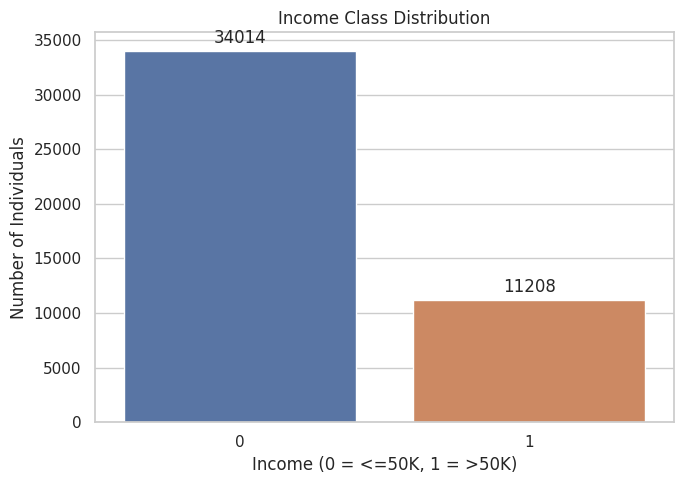

In [ ]:
if "income" not in df.columns:
    raise ValueError("Expected target column 'income' was not found in the dataset.")

# Map <=50K to 0 and >50K to 1
df["income"] = df["income"].map({"<=50K": 0, ">50K": 1})

if df["income"].isna().any():
    raise ValueError("Unexpected labels found in 'income'. Check df['income'].value_counts().")

print("Class counts:")
display(df["income"].value_counts().sort_index().rename(index={0: "<=50K (0)", 1: ">50K (1)"}).to_frame("count"))
print("\nClass percentages:")
display((df["income"].value_counts(normalize=True).sort_index() * 100)
        .round(2).rename(index={0: "<=50K (0)", 1: ">50K (1)"}).to_frame("percent"))

plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df, x="income", hue="income", order=[0, 1], legend=False)
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)
plt.title("Income Class Distribution")
plt.xlabel("Income (0 = <=50K, 1 = >50K)")
plt.ylabel("Number of Individuals")
plt.tight_layout()
plt.show()

### Interpretation: Income groups

The target column was turned into numbers: 0 means income of $50K or less, and 1 means more than $50K.

- 34,014 people (75.22%) earn $50K or less.
- 11,208 people (24.78%) earn more than $50K.

The groups are not balanced, with roughly three people in the lower group for every one in the higher group. This matters because a model that simply said "$50K or less" for everybody would already be right about 75% of the time. Accuracy alone can therefore look better than the model really is, and that is why precision, recall, F1-score and ROC-AUC are also used later in the notebook.

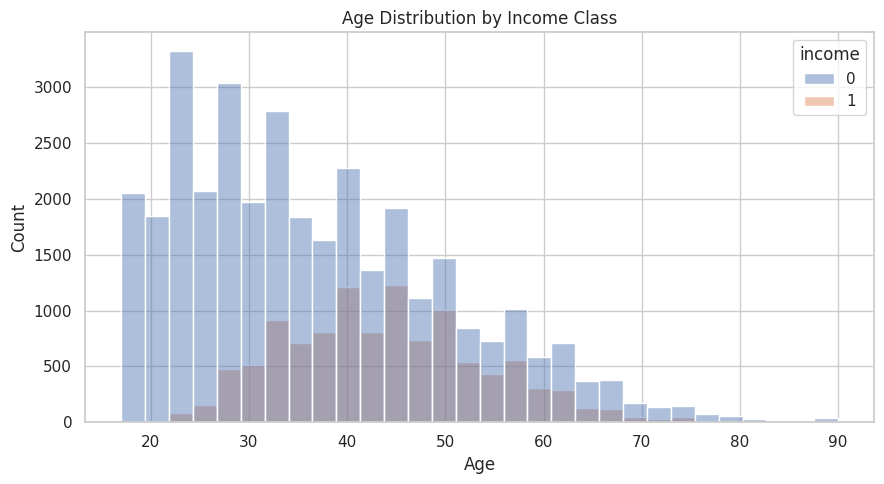

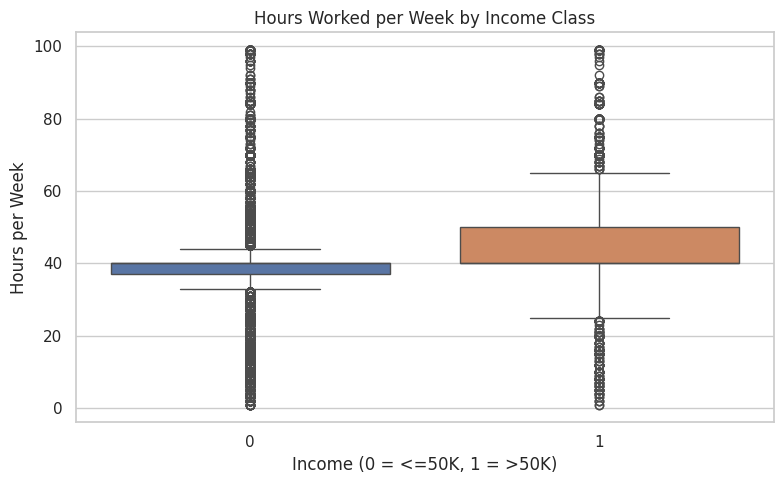

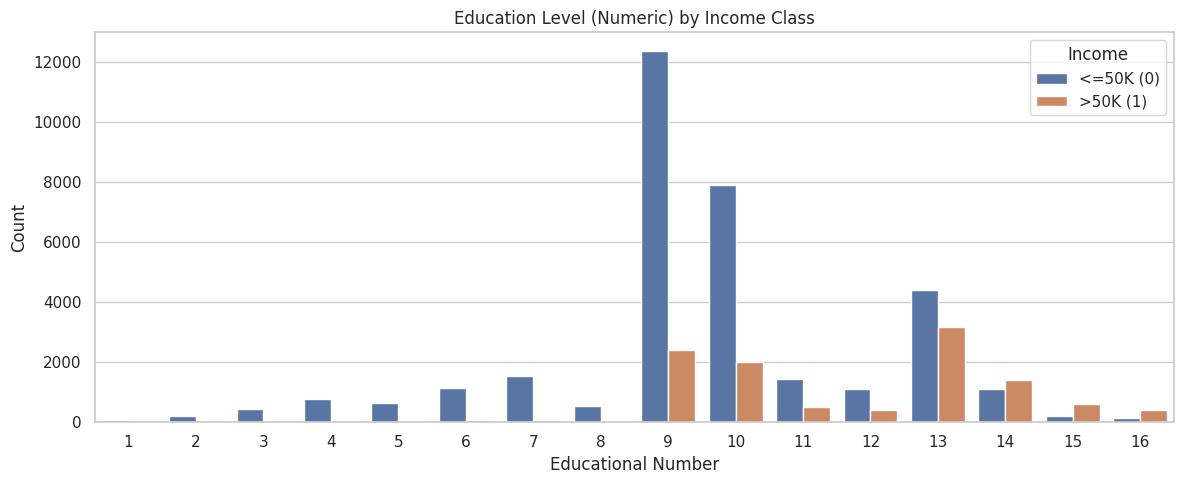

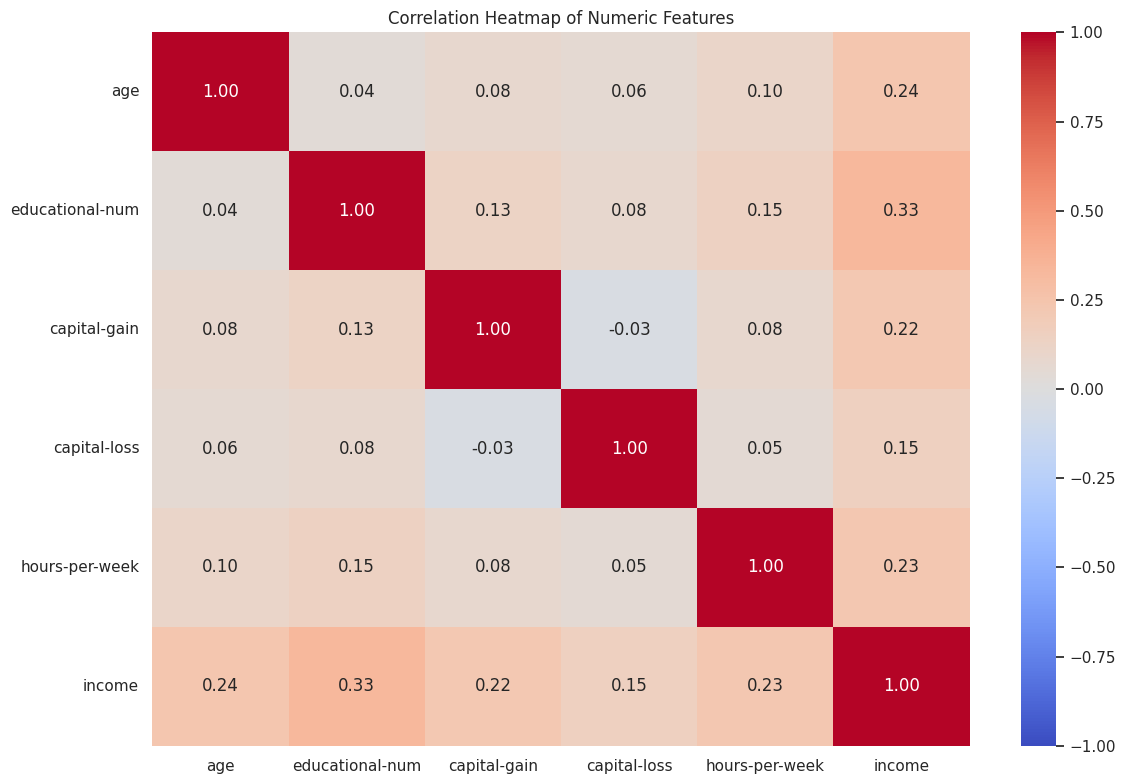

In [ ]:
# Age distribution by income class
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="age", hue="income", bins=30, multiple="layer", alpha=0.45)
plt.title("Age Distribution by Income Class")
plt.xlabel("Age")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

# Weekly working hours by income class
if "hours-per-week" in df.columns:
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=df, x="income", y="hours-per-week", hue="income", legend=False)
    plt.title("Hours Worked per Week by Income Class")
    plt.xlabel("Income (0 = <=50K, 1 = >50K)")
    plt.ylabel("Hours per Week")
    plt.tight_layout()
    plt.show()

# Numeric education level by income class
if "educational-num" in df.columns:
    plt.figure(figsize=(12, 5))
    sns.countplot(data=df, x="educational-num", hue="income")
    plt.title("Education Level (Numeric) by Income Class")
    plt.xlabel("Educational Number")
    plt.ylabel("Count")
    plt.legend(title="Income", labels=["<=50K (0)", ">50K (1)"])
    plt.tight_layout()
    plt.show()

# Correlation heatmap using numeric columns plus encoded income
numeric_eda = df.select_dtypes(include=np.number).copy()
plt.figure(figsize=(12, 8))
sns.heatmap(numeric_eda.corr(), cmap="coolwarm", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f")
plt.title("Correlation Heatmap of Numeric Features")
plt.tight_layout()
plt.show()

### Interpretation: Exploring the data

**Age.** The lower income group (0) is concentrated in the 20s and early 30s. People earning more than $50K (1) are rare before the mid-20s and are most common between about 35 and 55. Income tends to rise with age and career length, and then it drops off after retirement age.

**Hours per week.** The typical person in the higher income group works around 40 to 50 hours a week, while the typical person in the lower group works close to 40. The higher group works somewhat longer hours overall. Both groups have many unusual points at the very low and very high ends, such as people working only a few hours or close to 100 hours.

**Education.** Education level makes a big difference. At the lowest levels (1 to 8) almost everyone is in the lower income group. Around levels 9 and 10 (high school and some college) the lower group is still much bigger. By level 13 (bachelor's degree) the two groups are fairly close, and at levels 14 to 16 (master's, professional and doctorate degrees) the higher income group is actually the bigger one.

**Correlation heatmap.** Each number shows how strongly two columns move together, where 0 means no link and 1 means a perfect link. Education has the strongest link with income (0.33), followed by age (0.24), hours per week (0.23), capital gain (0.22) and capital loss (0.15). All of these links are positive but fairly modest, so no single column explains income by itself. The links between the input columns themselves are all small (0.15 or below), which means they are not simply repeating each other.

In [ ]:
SEED = 42

X = df.drop(columns=["income"]).copy()
y = df["income"].astype("int32").copy()

X = pd.get_dummies(X, drop_first=True, dtype=int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

numeric_features = [
    col for col in ["age", "educational-num", "capital-gain", "capital-loss", "hours-per-week"]
    if col in X_train.columns
]

scaler = StandardScaler()
X_train = X_train.copy()
X_test = X_test.copy()

X_train.loc[:, numeric_features] = scaler.fit_transform(X_train[numeric_features])
X_test.loc[:, numeric_features] = scaler.transform(X_test[numeric_features])

X_train_np = X_train.to_numpy(dtype=np.float32)
X_test_np = X_test.to_numpy(dtype=np.float32)
y_train_np = y_train.to_numpy(dtype=np.float32)
y_test_np = y_test.to_numpy(dtype=np.int32)

print("Training feature shape:", X_train_np.shape)
print("Testing feature shape:", X_test_np.shape)
print("Training target shape:", y_train_np.shape)
print("Testing target shape:", y_test_np.shape)
print("Scaled numeric features:", numeric_features)

Training feature shape: (36177, 80)
Testing feature shape: (9045, 80)
Training target shape: (36177,)
Testing target shape: (9045,)
Scaled numeric features: ['age', 'educational-num', 'capital-gain', 'capital-loss', 'hours-per-week']


/tmp/ipykernel_6331/3077045662.py:23: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[-0.26789621 -1.47640119 -0.8721487  ...  0.26082472 -1.17427495
 -1.47640119]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  X_train.loc[:, numeric_features] = scaler.fit_transform(X_train[numeric_features])
/tmp/ipykernel_6331/3077045662.py:23: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[-0.43615486 -0.43615486 -0.43615486 ...  1.90323196  1.12343636
 -0.43615486]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  X_train.loc[:, numeric_features] = scaler.fit_transform(X_train[numeric_features])
/tmp/ipykernel_6331/3077045662.py:23: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[-0.14779435 -0.14779435 -0.

### Interpretation: Preparing the data for the model

The text columns were converted into 0/1 columns (one-hot encoding), which grew the input from 12 columns to 80. The data was then split into a training part (36,177 people, 80%) and a test part (9,045 people, 20%). The split keeps the same 75/25 income mix in both parts, so the test is fair.

Five numeric columns (age, education number, capital gain, capital loss, hours per week) were rescaled to a common range. The scaling values were learned from the training data only and then applied to the test data, so the test data stays truly unseen.

The warnings shown are about data types inside pandas. They do not change the results.

Model: "sequential_26"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_78 (Dense)                │ (None, 128)            │        10,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_79 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_80 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,689 (73.00 KB)

 Trainable params: 18,689 (73.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8441 - loss: 0.3365 - val_accuracy: 0.8507 - val_loss: 0.3216
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8523 - loss: 0.3146 - val_accuracy: 0.8530 - val_loss: 0.3194
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8545 - loss: 0.3108 - val_accuracy: 0.8521 - val_loss: 0.3189
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8556 - loss: 0.3079 - val_accuracy: 0.8535 - val_loss: 0.3184
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8575 - loss: 0.3055 - val_accuracy: 0.8530 - val_loss: 0.3179
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8586 - loss: 0.3031 - val_accuracy: 0.8527 - val_loss: 0.3179
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8596 - loss: 0.3009 - val_accuracy: 0.8532 - val_loss: 0.3175
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8605 - loss: 0.2988 - val_accuracy: 0.

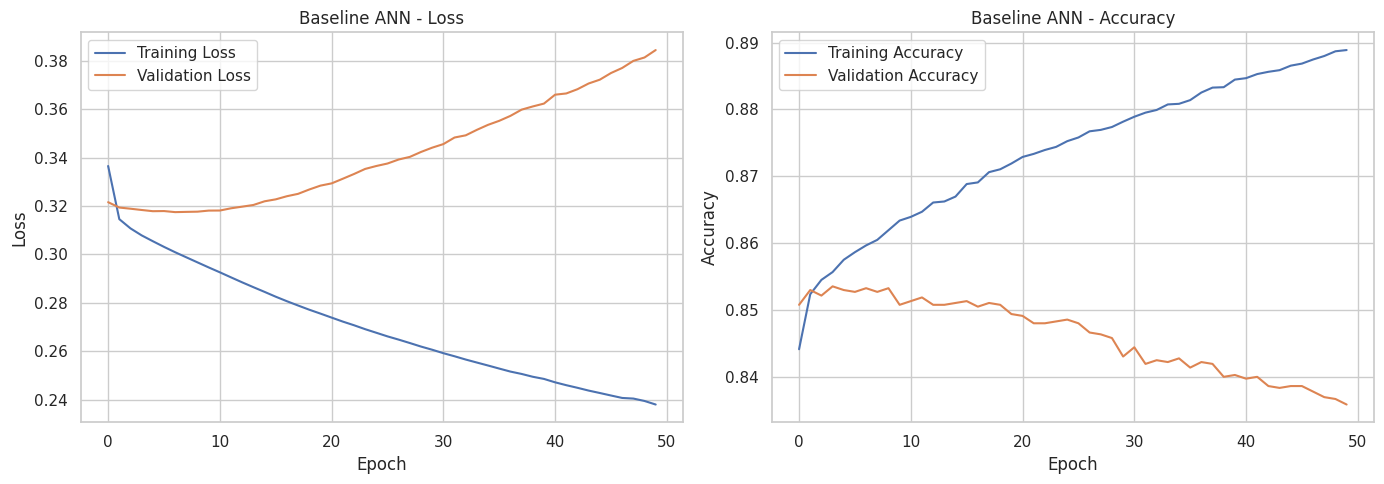

Baseline ANN Evaluation
-----------------------
Accuracy: 0.8269
Precision: 0.6785
Recall: 0.5731
F1-score: 0.6214
ROC-AUC: 0.8815

Classification Report:
              precision    recall  f1-score   support

       <=50K       0.87      0.91      0.89      6803
        >50K       0.68      0.57      0.62      2242

    accuracy                           0.83      9045
   macro avg       0.77      0.74      0.75      9045
weighted avg       0.82      0.83      0.82      9045



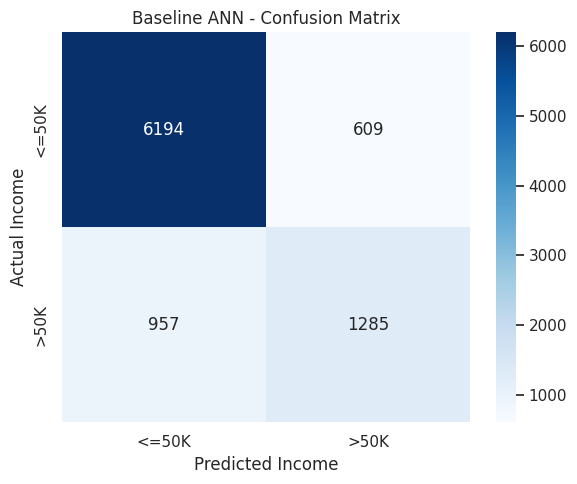

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.initializers import GlorotUniform
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Set random seed
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

# 1. Build the Baseline ANN
def build_ann(input_dim):
    model = Sequential([
        Input(shape=(input_dim,)),
        Dense(128, activation="relu",
              kernel_initializer=GlorotUniform(seed=SEED)),
        Dense(64, activation="relu",
              kernel_initializer=GlorotUniform(seed=SEED)),
        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=Adam(),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


baseline_model = build_ann(
    input_dim=X_train_np.shape[1]
)

baseline_model.summary()


baseline_history = baseline_model.fit(
    X_train_np,
    y_train_np,
    epochs=50,
    batch_size=64,
    validation_split=0.10,
    verbose=1
)



fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(baseline_history.history["loss"],
             label="Training Loss")
axes[0].plot(baseline_history.history["val_loss"],
             label="Validation Loss")
axes[0].set_title("Baseline ANN - Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(baseline_history.history["accuracy"],
             label="Training Accuracy")
axes[1].plot(baseline_history.history["val_accuracy"],
             label="Validation Accuracy")
axes[1].set_title("Baseline ANN - Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()


y_prob = baseline_model.predict(
    X_test_np, verbose=0
).ravel()

y_pred = (y_prob >= 0.5).astype(int)
y_true = np.asarray(y_test_np).astype(int).ravel()


print("Baseline ANN Evaluation")
print("-----------------------")
print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Precision:", round(precision_score(
    y_true, y_pred, zero_division=0
), 4))
print("Recall:", round(recall_score(
    y_true, y_pred, zero_division=0
), 4))
print("F1-score:", round(f1_score(
    y_true, y_pred, zero_division=0
), 4))
print("ROC-AUC:", round(roc_auc_score(y_true, y_prob), 4))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["<=50K", ">50K"],
    zero_division=0
))



cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["<=50K", ">50K"],
    yticklabels=["<=50K", ">50K"]
)
plt.title("Baseline ANN - Confusion Matrix")
plt.xlabel("Predicted Income")
plt.ylabel("Actual Income")
plt.tight_layout()
plt.show()

### Interpretation: Baseline neural network

This first model has two hidden layers (128 and 64 units) and about 18,700 adjustable values, and it was trained for 50 rounds.

**Training curves.** The training loss keeps falling and the training accuracy keeps rising (to about 89%). The validation curves tell a different story: validation loss is lowest in the first few rounds (around 0.32) and then climbs steadily to about 0.38, while validation accuracy slips from about 85% down to about 84%. This is overfitting. After the first few rounds the model starts memorising the training data instead of learning patterns that carry over to new people.

**Test results.** Accuracy is 82.7%, precision is 0.68, recall is 0.57, F1-score is 0.62 and ROC-AUC is 0.88. In plain terms, when the model says someone earns more than $50K it is right about 68% of the time, and it finds only about 57% of the people who really do. It is much better at the larger group: the "$50K or less" class scores 0.89 on F1, against 0.62 for the higher income class.

This is the starting point that the later experiments try to beat.

In [ ]:
from tensorflow.keras.initializers import GlorotUniform
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

activation_functions = ["relu", "tanh", "sigmoid", "elu"]

activation_results = []
activation_histories = {}
activation_models = {}

for activation in activation_functions:
    print(f"\nTraining model with {activation.upper()} activation")

    model = Sequential([
        Input(shape=(X_train_np.shape[1],)),
        Dense(128, activation=activation,
              kernel_initializer=GlorotUniform(seed=SEED)),
        Dense(64, activation=activation,
              kernel_initializer=GlorotUniform(seed=SEED)),
        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=Adam(),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    history = model.fit(
        X_train_np,
        y_train_np,
        epochs=15,
        batch_size=64,
        validation_split=0.10,
        verbose=1
    )

    probabilities = model.predict(X_test_np, verbose=0).ravel()
    predictions = (probabilities >= 0.5).astype(int)
    y_true = np.asarray(y_test_np).astype(int).ravel()

    activation_results.append({
        "Activation": activation.upper(),
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1 Score": f1_score(y_true, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, probabilities)
    })

    activation_histories[activation] = history
    activation_models[activation] = model

activation_df = pd.DataFrame(activation_results)

print("\nActivation Function Comparison:")
display(activation_df.round(4))


Training model with RELU activation
Epoch 1/15
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8434 - loss: 0.3360 - val_accuracy: 0.8485 - val_loss: 0.3213
Epoch 2/15
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8516 - loss: 0.3150 - val_accuracy: 0.8510 - val_loss: 0.3196
Epoch 3/15
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8536 - loss: 0.3114 - val_accuracy: 0.8541 - val_loss: 0.3184
Epoch 4/15
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8549 - loss: 0.3085 - val_accuracy: 0.8527 - val_loss: 0.3180
Epoch 5/15
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8567 - loss: 0.3060 - val_accuracy: 0.8524 - val_loss: 0.3177
Epoch 6/15
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8580 - loss: 0.3036 - val_accuracy: 0.8532 - val_loss: 0.3174
Epoch 7/15
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8594 - loss: 0.3014 - val_accuracy: 0.8543 - val_loss: 0.3176
Epoch 8/15
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8

,Activation,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,RELU,0.8488,0.7300,0.6186,0.6697,0.9042
1,TANH,0.8538,0.7406,0.6316,0.6818,0.9110
2,SIGMOID,0.8511,0.7377,0.6195,0.6735,0.9096
3,ELU,0.8531,0.7371,0.6329,0.6811,0.9103


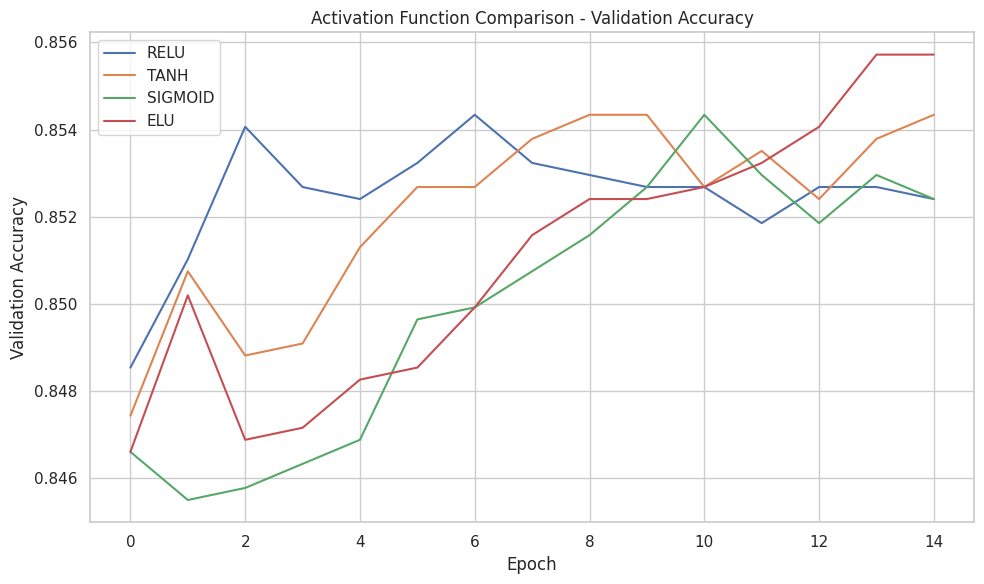

In [ ]:
plt.figure(figsize=(10, 6))

for activation, history in activation_histories.items():
    plt.plot(
        history.history["val_accuracy"],
        label=activation.upper()
    )

plt.title("Activation Function Comparison - Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

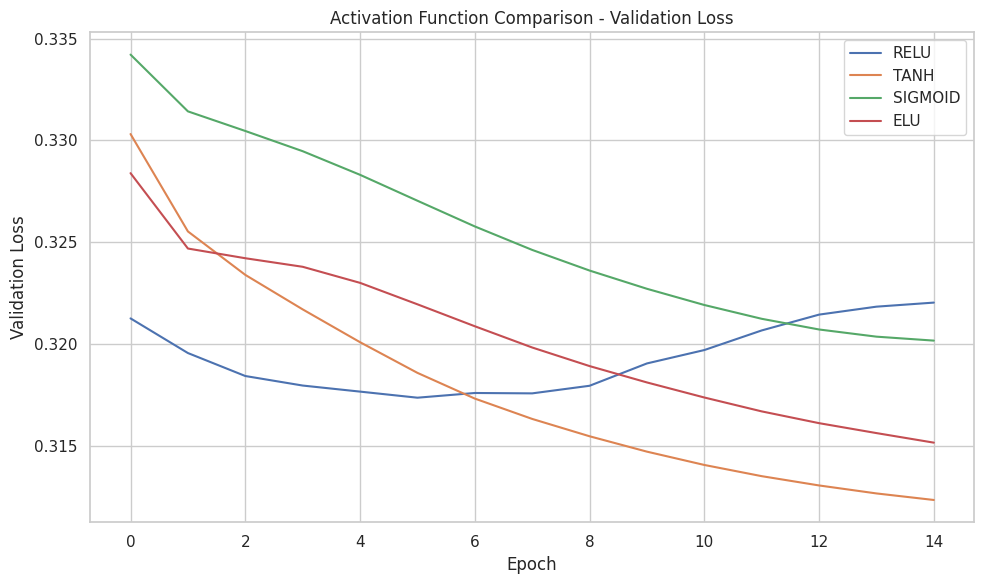

In [ ]:
plt.figure(figsize=(10, 6))

for activation, history in activation_histories.items():
    plt.plot(
        history.history["val_loss"],
        label=activation.upper()
    )

plt.title("Activation Function Comparison - Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Interpretation: Comparing activation functions

An activation function decides how each unit in the network responds to its input. Four were tried (ReLU, tanh, sigmoid and ELU), each trained for 15 rounds.

The results are very close. Accuracy ranges only from 84.9% to 85.4%, and ROC-AUC from 0.904 to 0.911. Tanh comes out slightly ahead on F1-score (0.682) and ROC-AUC (0.911), with ELU just behind it. ReLU is the lowest on the test table.

The charts show how the models behaved while training. Validation accuracy moves up and down within a narrow band of about 0.846 to 0.856 for all four. Validation loss for tanh and ELU keeps falling through the 15 rounds, while ReLU's validation loss reaches its lowest point early and then starts to creep up, which is an early sign of overfitting.

Overall the choice of activation function matters less than might be expected here, and the gaps between them are small.

In [ ]:
best_activation = activation_df.sort_values(
    by="F1 Score", ascending=False
).iloc[0]

print("Best activation based on F1 Score:")
print(best_activation)

Best activation based on F1 Score:
Activation        TANH
Accuracy      0.853842
Precision     0.740586
Recall        0.631579
F1 Score      0.681753
ROC-AUC       0.911019
Name: 1, dtype: object


### Interpretation: Best activation function

Ranked by F1-score, tanh is the winner with an F1 of 0.682, accuracy of 85.4%, precision of 0.74, recall of 0.63 and ROC-AUC of 0.911. F1-score is a fair way to choose because it balances catching high earners (recall) with being correct when the model says someone is one (precision).

Keep in mind that the winning margin is small (about 0.01 on F1), so this is a slight edge and not a decisive one.

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.initializers import (
    GlorotUniform, GlorotNormal,
    HeUniform, HeNormal, Zeros
)
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

initializers = {
    "Glorot Uniform": GlorotUniform(seed=SEED),
    "Glorot Normal": GlorotNormal(seed=SEED),
    "He Uniform": HeUniform(seed=SEED),
    "He Normal": HeNormal(seed=SEED),
    "Zeros": Zeros()
}

initializer_results = []
initializer_histories = {}
initializer_models = {}

for name, initializer in initializers.items():
    print(f"\nTraining with {name}")

    model = Sequential([
        Input(shape=(X_train_np.shape[1],)),
        Dense(128, activation="relu",
              kernel_initializer=initializer),
        Dense(64, activation="relu",
              kernel_initializer=initializer),
        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=Adam(),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    history = model.fit(
        X_train_np, y_train_np,
        epochs=15,
        batch_size=64,
        validation_split=0.10,
        verbose=1
    )

    probabilities = model.predict(X_test_np, verbose=0).ravel()
    predictions = (probabilities >= 0.5).astype(int)
    y_true = np.asarray(y_test_np).astype(int).ravel()

    initializer_results.append({
        "Initializer": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1 Score": f1_score(y_true, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, probabilities)
    })

    initializer_histories[name] = history
    initializer_models[name] = model

initializer_df = pd.DataFrame(initializer_results)

print("\nWeight Initializer Comparison:")
display(initializer_df.round(4))


Training with Glorot Uniform
Epoch 1/15
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8393 - loss: 0.3399 - val_accuracy: 0.8502 - val_loss: 0.3207
Epoch 2/15
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8522 - loss: 0.3147 - val_accuracy: 0.8499 - val_loss: 0.3189
Epoch 3/15
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8544 - loss: 0.3109 - val_accuracy: 0.8513 - val_loss: 0.3180
Epoch 4/15
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8556 - loss: 0.3080 - val_accuracy: 0.8532 - val_loss: 0.3176
Epoch 5/15
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8579 - loss: 0.3055 - val_accuracy: 0.8516 - val_loss: 0.3176
Epoch 6/15
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8586 - loss: 0.3031 - val_accuracy: 0.8519 - val_loss: 0.3178
Epoch 7/15
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8603 - loss: 0.3009 - val_accuracy: 0.8524 - val_loss: 0.3186
Epoch 8/15
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8611 - l

,Initializer,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Glorot Uniform,0.8490,0.7293,0.6213,0.6710,0.9047
1,Glorot Normal,0.8480,0.7355,0.6039,0.6632,0.9076
2,He Uniform,0.8477,0.7276,0.6160,0.6671,0.9038
3,He Normal,0.8471,0.7264,0.6146,0.6659,0.9042
4,Zeros,0.7521,0.0000,0.0000,0.0000,0.5005


### Interpretation: Comparing weight initializers

Before training starts, a network needs starting values for its weights. Five ways of choosing them were compared.

The four standard methods (Glorot Uniform, Glorot Normal, He Uniform, He Normal) give almost identical results, with accuracy near 84.8%, F1-score between 0.663 and 0.671 and ROC-AUC around 0.904 to 0.908.

The odd one out is **Zeros**. Starting every weight at zero is a known mistake. All the units begin identical and receive identical updates, so the network cannot learn different things in different units. The result is accuracy of 75.2% (which is just the share of the larger group), precision and recall of 0, and ROC-AUC of 0.50, which is no better than a coin toss. In practice the model predicted "$50K or less" for everybody.

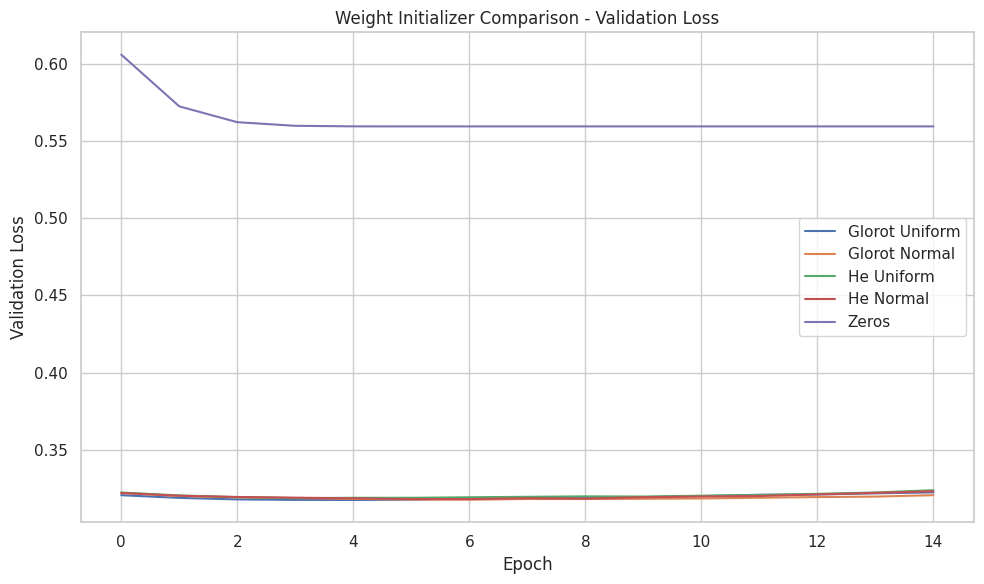

In [ ]:
plt.figure(figsize=(10, 6))

for name, history in initializer_histories.items():
    plt.plot(history.history["val_loss"], label=name)

plt.title("Weight Initializer Comparison - Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
best_initializer = initializer_df.sort_values(
    by="F1 Score", ascending=False
).iloc[0]

print("Best initializer based on F1 Score:")
print(best_initializer)

Best initializer based on F1 Score:
Initializer    Glorot Uniform
Accuracy             0.848977
Precision            0.729319
Recall                0.62132
F1 Score             0.671002
ROC-AUC              0.904739
Name: 0, dtype: object


### Interpretation: Best initializer

The validation loss chart shows the story clearly. The four proper initializers sit together at the bottom of the chart around 0.32, while the Zeros line is stuck far above them at about 0.56 and never improves. This means the Zeros model did not learn at all.

By F1-score, Glorot Uniform is the best at 0.671. The lead over the other three methods is tiny, so any of them would work well. What matters most is avoiding zeros.

In [ ]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.initializers import HeNormal
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score
)
from sklearn.utils.class_weight import compute_class_weight


def focal_loss(gamma=2.0, alpha=0.25):
    def loss_function(y_true, y_pred):
        y_true = tf.cast(tf.reshape(y_true, (-1, 1)), tf.float32)

        y_pred = tf.clip_by_value(
            y_pred,
            tf.keras.backend.epsilon(),
            1.0 - tf.keras.backend.epsilon()
        )

        p_t = (
            y_true * y_pred
            + (1.0 - y_true) * (1.0 - y_pred)
        )

        alpha_t = (
            y_true * alpha
            + (1.0 - y_true) * (1.0 - alpha)
        )

        loss = -alpha_t * tf.pow(1.0 - p_t, gamma) * tf.math.log(p_t)

        return tf.reduce_mean(loss)

    return loss_function

### Interpretation: Focal loss

This cell defines a custom loss called focal loss. It is designed for unbalanced data. It makes the model pay less attention to easy examples (the many clear "$50K or less" cases) and more attention to hard ones. The settings `gamma=2.0` and `alpha=0.25` control how strongly this effect is applied. Nothing is displayed here because the cell only defines the function.

In [ ]:
classes = np.array([0, 1])

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=np.asarray(y_train_np).astype(int)
)

class_weight_dict = {
    int(cls): float(weight)
    for cls, weight in zip(classes, class_weights)
}

print("Class weights:", class_weight_dict)

Class weights: {0: 0.6647495498144133, 1: 2.0174548293553425}


### Interpretation: Class weights

Because the lower income group is much bigger, the model is told to treat mistakes on the smaller group as more serious. Mistakes on a high earner count about 2.02 times, and mistakes on a lower earner count about 0.66 times. This pushes the model to pay more attention to the group it would otherwise ignore.

In [ ]:
loss_functions = {
    "Binary Cross-Entropy": "binary_crossentropy",
    "Mean Squared Error": "mse",
    "Weighted BCE": "binary_crossentropy",
    "Focal Loss": focal_loss(gamma=2.0, alpha=0.25)
}

loss_results = []
loss_histories = {}
loss_models = {}

for name, loss_function in loss_functions.items():

    print(f"\nTraining with {name}")

    model = Sequential([
        Input(shape=(X_train_np.shape[1],)),
        Dense(128, activation="relu",
              kernel_initializer=HeNormal(seed=42)),
        Dense(64, activation="relu",
              kernel_initializer=HeNormal(seed=42)),
        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=Adam(),
        loss=loss_function,
        metrics=["accuracy"]
    )

    fit_args = {}

    if name == "Weighted BCE":
        fit_args["class_weight"] = class_weight_dict

    history = model.fit(
        X_train_np,
        y_train_np,
        epochs=15,
        batch_size=64,
        validation_split=0.10,
        verbose=1,
        **fit_args
    )

    probabilities = model.predict(
        X_test_np, verbose=0
    ).ravel()

    predictions = (probabilities >= 0.5).astype(int)
    y_true = np.asarray(y_test_np).astype(int).ravel()

    loss_results.append({
        "Loss Function": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, probabilities)
    })

    loss_histories[name] = history
    loss_models[name] = model

loss_df = pd.DataFrame(loss_results)

print("\nLoss Function Comparison:")
display(loss_df.round(4))


Training with Binary Cross-Entropy
Epoch 1/15
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8424 - loss: 0.3359 - val_accuracy: 0.8483 - val_loss: 0.3211
Epoch 2/15
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8533 - loss: 0.3146 - val_accuracy: 0.8491 - val_loss: 0.3191
Epoch 3/15
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8553 - loss: 0.3104 - val_accuracy: 0.8510 - val_loss: 0.3188
Epoch 4/15
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8570 - loss: 0.3072 - val_accuracy: 0.8513 - val_loss: 0.3186
Epoch 5/15
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8577 - loss: 0.3044 - val_accuracy: 0.8507 - val_loss: 0.3186
Epoch 6/15
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8586 - loss: 0.3019 - val_accuracy: 0.8502 - val_loss: 0.3188
Epoch 7/15
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8601 - loss: 0.2996 - val_accuracy: 0.8502 - val_loss: 0.3192
Epoch 8/15
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.86

,Loss Function,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Binary Cross-Entropy,0.8496,0.7323,0.6200,0.6715,0.9059
1,Mean Squared Error,0.8443,0.7104,0.6280,0.6667,0.9048
2,Weighted BCE,0.8057,0.5738,0.8408,0.6821,0.9037
3,Focal Loss,0.8202,0.8658,0.3252,0.4728,0.8989


In [ ]:
loss_functions = {
    "Binary Cross-Entropy": "binary_crossentropy",
    "Mean Squared Error": "mse",
    "Weighted BCE": "binary_crossentropy",
    "Focal Loss": focal_loss(gamma=2.0, alpha=0.25)
}

loss_results = []
loss_histories = {}
loss_models = {}

for name, loss_function in loss_functions.items():

    print(f"\nTraining with {name}")

    model = Sequential([
        Input(shape=(X_train_np.shape[1],)),
        Dense(128, activation="relu",
              kernel_initializer=HeNormal(seed=42)),
        Dense(64, activation="relu",
              kernel_initializer=HeNormal(seed=42)),
        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=Adam(),
        loss=loss_function,
        metrics=["accuracy"]
    )

    fit_args = {}

    if name == "Weighted BCE":
        fit_args["class_weight"] = class_weight_dict

    history = model.fit(
        X_train_np,
        y_train_np,
        epochs=15,
        batch_size=64,
        validation_split=0.10,
        verbose=1,
        **fit_args
    )

    probabilities = model.predict(
        X_test_np, verbose=0
    ).ravel()

    predictions = (probabilities >= 0.5).astype(int)
    y_true = np.asarray(y_test_np).astype(int).ravel()

    loss_results.append({
        "Loss Function": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, probabilities)
    })

    loss_histories[name] = history
    loss_models[name] = model

loss_df = pd.DataFrame(loss_results)

print("\nLoss Function Comparison:")
display(loss_df.round(4))


Training with Binary Cross-Entropy
Epoch 1/15
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8427 - loss: 0.3354 - val_accuracy: 0.8480 - val_loss: 0.3214
Epoch 2/15
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8526 - loss: 0.3149 - val_accuracy: 0.8499 - val_loss: 0.3193
Epoch 3/15
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8551 - loss: 0.3105 - val_accuracy: 0.8491 - val_loss: 0.3186
Epoch 4/15
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8572 - loss: 0.3071 - val_accuracy: 0.8507 - val_loss: 0.3178
Epoch 5/15
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8588 - loss: 0.3040 - val_accuracy: 0.8488 - val_loss: 0.3175
Epoch 6/15
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8603 - loss: 0.3013 - val_accuracy: 0.8530 - val_loss: 0.3174
Epoch 7/15
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8610 - loss: 0.2985 - val_accuracy: 0.8527 - val_loss: 0.3179
Epoch 8/15
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.86

,Loss Function,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Binary Cross-Entropy,0.8459,0.7272,0.6053,0.6607,0.9037
1,Mean Squared Error,0.8493,0.7262,0.6293,0.6743,0.9072
2,Weighted BCE,0.8046,0.5723,0.8390,0.6804,0.9031
3,Focal Loss,0.8237,0.8512,0.3497,0.4957,0.9019


### Interpretation: Comparing loss functions

A loss function is the score the model tries to reduce while learning. Four were compared. This experiment was run twice (the cell above and this one) and the numbers differ a little between the two runs. This is normal for neural networks, and it is a useful reminder that very small gaps between models should not be over-read.

- **Binary cross-entropy** (the standard choice) gives accuracy around 85%, precision around 0.73 and recall around 0.61.
- **Mean squared error** performs about the same, with accuracy around 84.5% to 85% and F1 close to 0.67.
- **Weighted BCE** gives up some accuracy (about 80.5%) and precision (about 0.57) but raises recall to about 0.84. It finds far more high earners, at the price of more false alarms.
- **Focal loss** goes the other way. Its precision is very high (about 0.85 to 0.87), but recall falls to about 0.33 to 0.35. It only labels someone as a high earner when it is very sure, so it misses most of them. Its F1 of 0.47 to 0.50 is the lowest.

The right choice depends on what matters more. If missing a high earner is costly, weighted BCE is attractive. If false alarms are costly, focal loss is the more careful option. For an all-round balance, standard binary cross-entropy is a good option.

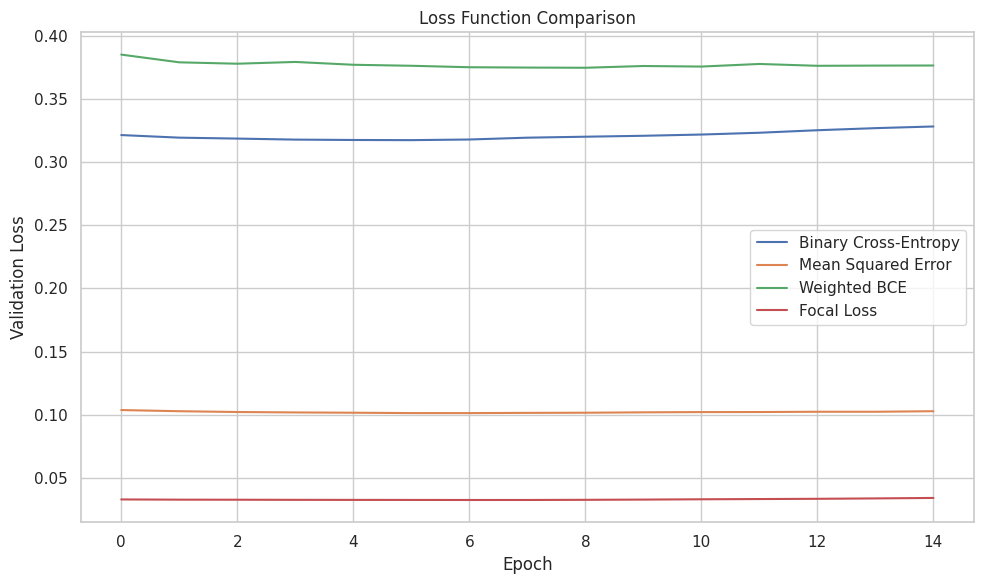

In [ ]:
plt.figure(figsize=(10, 6))

for name, history in loss_histories.items():
    plt.plot(
        history.history["val_loss"],
        label=name
    )

plt.title("Loss Function Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
best_loss = loss_df.sort_values(
    by="F1 Score",
    ascending=False
).iloc[0]

print("Best loss function based on F1-score:")
print(best_loss)

Best loss function based on F1-score:
Loss Function    Weighted BCE
Accuracy             0.804643
Precision            0.572254
Recall               0.838983
F1 Score             0.680412
ROC-AUC              0.903095
Name: 2, dtype: object


### Interpretation: Best loss function

The loss comparison chart should not be read as a ranking. Each line is measured on a different scale (for example, focal loss values are naturally tiny and mean squared error values are small), so a lower line does not mean a better model. The tables of accuracy, precision, recall and F1 are the right way to compare them.

By F1-score alone, Weighted BCE comes out first at 0.680, but only slightly ahead of mean squared error (0.674) and standard binary cross-entropy (0.661) in this run. It also has much lower accuracy than they do (about 80% against about 85%). It is best described as the model that is most willing to flag high earners, not the most accurate one.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, BatchNormalization, Activation
from tensorflow.keras.initializers import HeNormal
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

batchnorm_results = []
batchnorm_histories = {}
batchnorm_models = {}

for use_bn in [False, True]:
    name = "With Batch Normalization" if use_bn else "Without Batch Normalization"

    print(f"\nTraining: {name}")

    model = Sequential()
    model.add(Input(shape=(X_train_np.shape[1],)))

    model.add(Dense(128, kernel_initializer=HeNormal(seed=SEED)))
    if use_bn:
        model.add(BatchNormalization())
    model.add(Activation("relu"))

    model.add(Dense(64, kernel_initializer=HeNormal(seed=SEED)))
    if use_bn:
        model.add(BatchNormalization())
    model.add(Activation("relu"))

    model.add(Dense(1, activation="sigmoid"))

    model.compile(
        optimizer=Adam(),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    history = model.fit(
        X_train_np,
        y_train_np,
        epochs=20,
        batch_size=64,
        validation_split=0.10,
        verbose=1
    )

    probabilities = model.predict(X_test_np, verbose=0).ravel()
    predictions = (probabilities >= 0.5).astype(int)
    y_true = np.asarray(y_test_np).astype(int).ravel()

    batchnorm_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1 Score": f1_score(y_true, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, probabilities)
    })

    batchnorm_histories[name] = history
    batchnorm_models[name] = model

batchnorm_df = pd.DataFrame(batchnorm_results)
display(batchnorm_df.round(4))


Training: Without Batch Normalization
Epoch 1/20
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8438 - loss: 0.3351 - val_accuracy: 0.8491 - val_loss: 0.3202
Epoch 2/20
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8537 - loss: 0.3148 - val_accuracy: 0.8485 - val_loss: 0.3186
Epoch 3/20
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8556 - loss: 0.3106 - val_accuracy: 0.8510 - val_loss: 0.3180
Epoch 4/20
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8574 - loss: 0.3073 - val_accuracy: 0.8505 - val_loss: 0.3178
Epoch 5/20
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8589 - loss: 0.3043 - val_accuracy: 0.8507 - val_loss: 0.3178
Epoch 6/20
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8598 - loss: 0.3016 - val_accuracy: 0.8505 - val_loss: 0.3180
Epoch 7/20
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8607 - loss: 0.2990 - val_accuracy: 0.8474 - val_loss: 0.3183
Epoch 8/20
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Without Batch Normalization,0.8461,0.7173,0.6258,0.6684,0.9021
1,With Batch Normalization,0.8353,0.6785,0.6374,0.6573,0.8924


### Interpretation: Batch normalization

Batch normalization is a technique that keeps the numbers inside the network on a steady scale, which often makes training smoother. Here it did not help. The model without it scored better on every measure: accuracy of 84.6% against 83.5%, precision of 0.72 against 0.68, F1 of 0.668 against 0.657 and ROC-AUC of 0.902 against 0.892. Recall was the only measure slightly higher with batch normalization (0.637 against 0.626).

This result is specific to this small network and this dataset, and it should not be taken as a general rule against batch normalization.

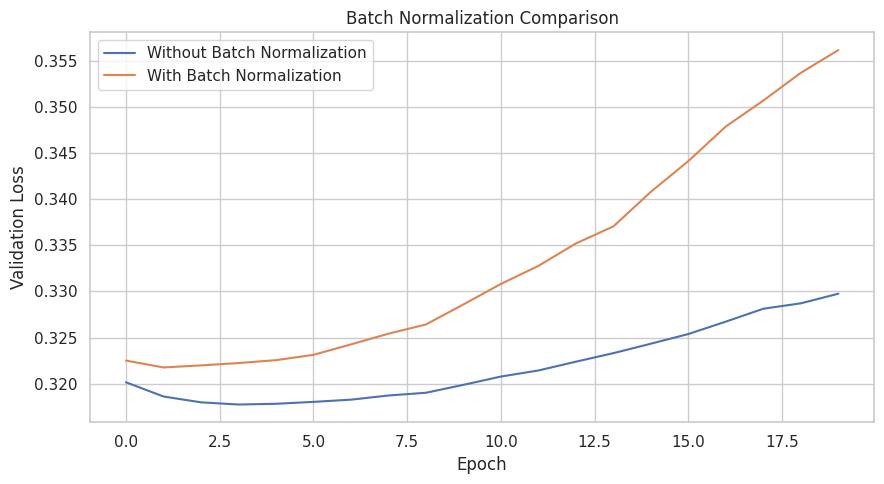

In [ ]:
plt.figure(figsize=(9, 5))

for name, history in batchnorm_histories.items():
    plt.plot(history.history["val_loss"], label=name)

plt.title("Batch Normalization Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

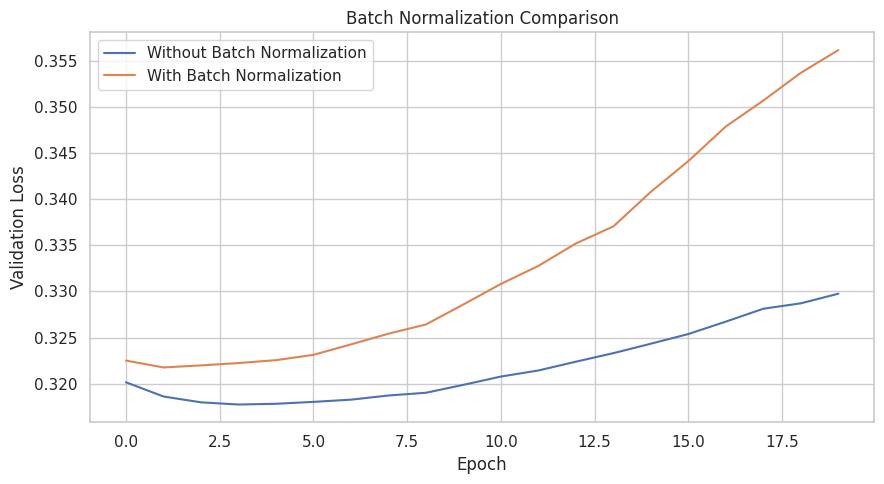

In [ ]:
plt.figure(figsize=(9, 5))

for name, history in batchnorm_histories.items():
    plt.plot(history.history["val_loss"], label=name)

plt.title("Batch Normalization Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

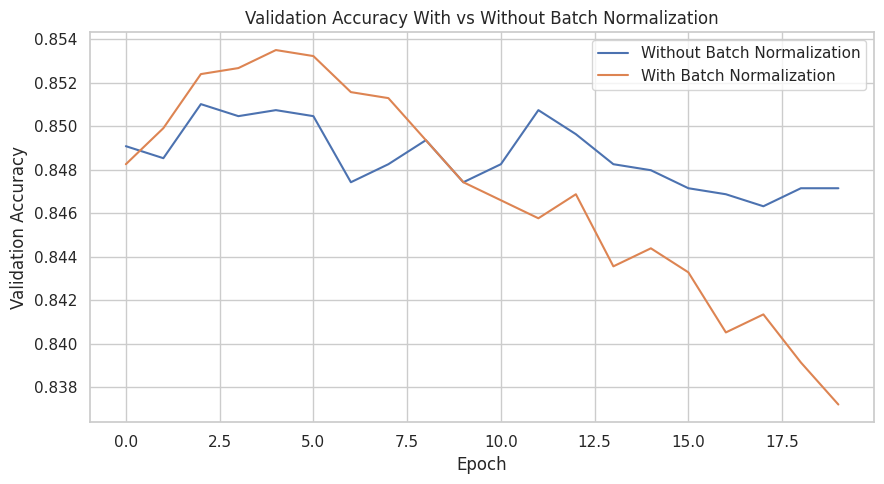

In [ ]:
plt.figure(figsize=(9, 5))

for name, history in batchnorm_histories.items():
    plt.plot(history.history["val_accuracy"], label=name)

plt.title("Validation Accuracy With vs Without Batch Normalization")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Interpretation: Batch normalization charts

The validation loss chart shows that the model with batch normalization starts at a slightly higher loss and then rises much faster as training continues, so it overfits more quickly. The model without it also rises, but more gently.

The validation accuracy chart shows the same pattern. The batch normalization model reaches the higher peak early (about 85.3% around round 4) but then falls to about 83.7% by round 20, ending below the plain model.

The lesson is that both versions get worse if trained for too long, which is exactly the problem that early stopping (used in the final model) is meant to fix. The cell that draws the validation loss chart appears twice in the notebook, so the second chart is a repeat of the first.

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, BatchNormalization, Activation
from tensorflow.keras.initializers import HeNormal
from tensorflow.keras.optimizers import SGD, RMSprop, Adam
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

SEED = 42
tf.keras.utils.set_random_seed(SEED)

# Build the neural network
def build_optimizer_model(optimizer):
    model = Sequential([
        Input(shape=(X_train_np.shape[1],)),
        Dense(128, kernel_initializer=HeNormal(seed=SEED)),
        BatchNormalization(),
        Activation("relu"),
        Dense(64, kernel_initializer=HeNormal(seed=SEED)),
        BatchNormalization(),
        Activation("relu"),
        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model


# Compare different optimizers
optimizer_factories = {
    "SGD": lambda: SGD(learning_rate=0.01),
    "SGD + Momentum": lambda: SGD(
        learning_rate=0.01, momentum=0.9
    ),
    "RMSprop": lambda: RMSprop(learning_rate=0.001),
    "Adam (Default)": lambda: Adam(),
    "Adam (lr=0.001)": lambda: Adam(learning_rate=0.001)
}

optimizer_results = []
optimizer_histories = {}
optimizer_models = {}

for name, optimizer_factory in optimizer_factories.items():
    print("Training:", name)

    model = build_optimizer_model(optimizer_factory())

    history = model.fit(
        X_train_np,
        y_train_np,
        epochs=15,
        batch_size=64,
        validation_split=0.1,
        verbose=0
    )

    probabilities = model.predict(
        X_test_np, verbose=0
    ).ravel()

    predictions = (probabilities >= 0.5).astype(int)

    optimizer_results.append({
        "Optimizer": name,
        "Accuracy": accuracy_score(y_test_np, predictions),
        "Precision (Class 1)": precision_score(
            y_test_np, predictions, zero_division=0
        ),
        "Recall (Class 1)": recall_score(
            y_test_np, predictions, zero_division=0
        ),
        "F1-Score (Class 1)": f1_score(
            y_test_np, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test_np, probabilities),
        "Final Validation Accuracy":
            history.history["val_accuracy"][-1]
    })

    optimizer_histories[name] = history
    optimizer_models[name] = model


optimizer_df = pd.DataFrame(optimizer_results)
display(optimizer_df.round(4))


Training: SGD
Training: SGD + Momentum
Training: RMSprop
Training: Adam (Default)
Training: Adam (lr=0.001)


,Optimizer,Accuracy,Precision (Class 1),Recall (Class 1),F1-Score (Class 1),ROC-AUC,Final Validation Accuracy
0,SGD,0.8458,0.7211,0.6160,0.6644,0.9067,0.8524
1,SGD + Momentum,0.8446,0.7015,0.6490,0.6742,0.9034,0.8452
2,RMSprop,0.8438,0.7129,0.6191,0.6627,0.9007,0.8436
3,Adam (Default),0.8420,0.6938,0.6490,0.6707,0.9014,0.8425
4,Adam (lr=0.001),0.8452,0.7018,0.6530,0.6765,0.9011,0.8433


### Interpretation: Comparing optimizers

An optimizer is the method the network uses to adjust its weights while learning. Five settings were tested, all with batch normalization.

Everything is again close. Accuracy is between 84.2% and 84.6%, F1-score between 0.663 and 0.677, and ROC-AUC between 0.900 and 0.907. Adam with a learning rate of 0.001 has the best F1 (0.677), followed by SGD with momentum (0.674). Plain SGD has the best accuracy and ROC-AUC, and the highest precision, but it has the lowest recall of the five (0.616).

Adam (Default) and Adam (lr=0.001) are in fact the same setting, because 0.001 is Adam's default. Their small differences in the table come from random variation in training, which shows how much noise there is in these comparisons.

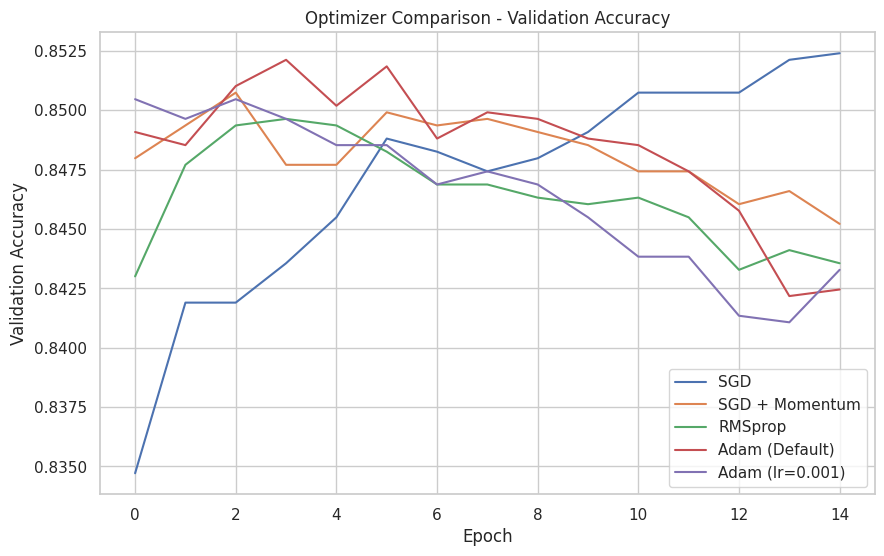

In [ ]:

plt.figure(figsize=(10, 6))

for name, history in optimizer_histories.items():
    plt.plot(
        history.history["val_accuracy"],
        label=name
    )

plt.title("Optimizer Comparison - Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()


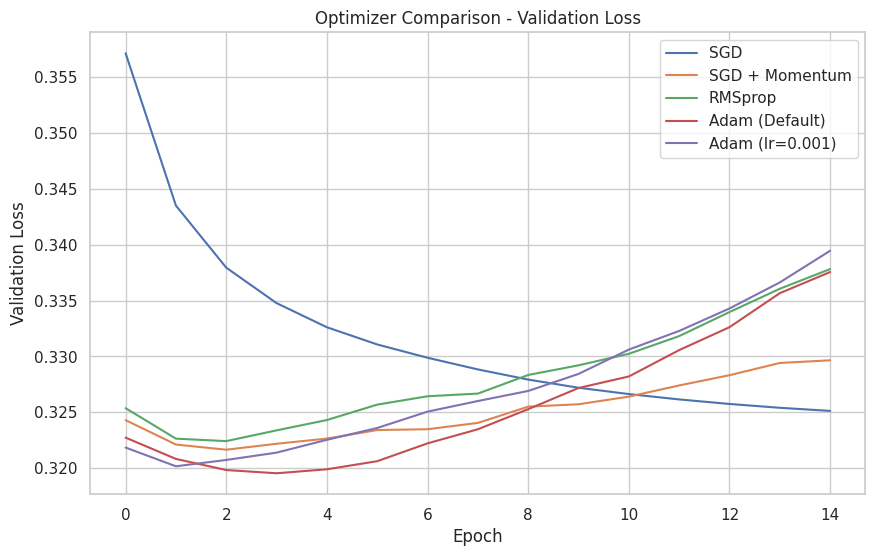

In [ ]:

plt.figure(figsize=(10, 6))

for name, history in optimizer_histories.items():
    plt.plot(
        history.history["val_loss"],
        label=name
    )

plt.title("Optimizer Comparison - Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


### Interpretation: Optimizer charts

Validation accuracy: the lines cross each other a lot and mostly drift downward as training goes on. Plain SGD behaves differently, starting low and improving slowly to end as the best line at about 85.2%, because it takes smaller, steadier steps. The faster optimizers (Adam, RMSprop, SGD with momentum) reach their best values in the first few rounds and then decline.

Validation loss: Adam and RMSprop reach their lowest loss (around 0.320) within the first 2 to 4 rounds and then rise, so they overfit if left running. SGD starts higher but keeps improving, and it has the lowest loss by the end of the chart.

The takeaway is that the fast optimizers learn quickly and then overfit, so stopping at the right time matters more than which optimizer is picked. This leads into the final model, which uses Adam together with early stopping.

In [ ]:

import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, BatchNormalization, Activation
from tensorflow.keras.initializers import HeNormal
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)

final_model = Sequential([
    Input(shape=(X_train_np.shape[1],)),

    Dense(128, kernel_initializer=HeNormal(seed=42)),
    BatchNormalization(),
    Activation("relu"),

    Dense(64, kernel_initializer=HeNormal(seed=42)),
    BatchNormalization(),
    Activation("relu"),

    Dense(1, activation="sigmoid")
])

final_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

final_history = final_model.fit(
    X_train_np,
    y_train_np,
    epochs=80,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stopping],
    verbose=1
)

print("Final model training completed!")


Epoch 1/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8397 - loss: 0.3442 - val_accuracy: 0.8521 - val_loss: 0.3234
Epoch 2/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8504 - loss: 0.3180 - val_accuracy: 0.8535 - val_loss: 0.3208
Epoch 3/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8541 - loss: 0.3113 - val_accuracy: 0.8521 - val_loss: 0.3200
Epoch 4/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8569 - loss: 0.3065 - val_accuracy: 0.8519 - val_loss: 0.3200
Epoch 5/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8597 - loss: 0.3023 - val_accuracy: 0.8516 - val_loss: 0.3208
Epoch 6/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8624 - loss: 0.2985 - val_accuracy: 0.8513 - val_loss: 0.3218
Epoch 7/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8639 - loss: 0.2950 - val_accuracy: 0.8483 - val_loss: 0.3231
Epoch 8/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8658 - loss: 0.2913 - val_accuracy: 0.

### Interpretation: Training the final model

The final model uses the pieces that worked best: two hidden layers with He Normal initialization, batch normalization, ReLU activations, the standard loss, and the Adam optimizer at its default learning rate. It was allowed up to 80 rounds, but **early stopping** was switched on. This watches the validation loss and stops once it has not improved for 5 rounds in a row, then goes back to the best version of the weights.

Training stopped after only 9 rounds, and the model kept the weights from around round 3 or 4, when validation loss was at its lowest (about 0.320). This prevents the overfitting that was seen in the baseline model, which was left running for 50 rounds.

FINAL MODEL CLASSIFICATION REPORT
              precision    recall  f1-score   support

       <=50K       0.89      0.92      0.90      6803
        >50K       0.72      0.64      0.68      2242

    accuracy                           0.85      9045
   macro avg       0.80      0.78      0.79      9045
weighted avg       0.85      0.85      0.85      9045

Accuracy: 0.8501
Precision (Class 1): 0.7228
Recall (Class 1): 0.6409
F1-Score (Class 1): 0.6794
ROC-AUC: 0.9085


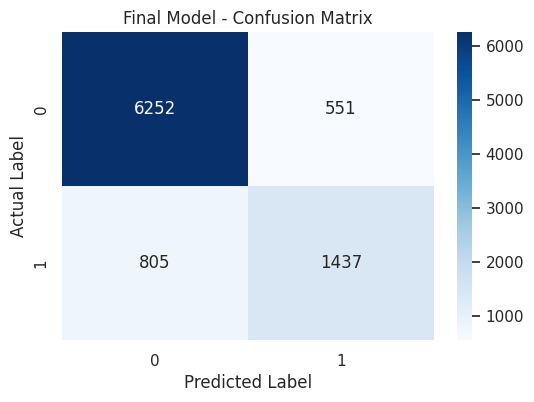

In [ ]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    confusion_matrix
)
import seaborn as sns

final_probabilities = final_model.predict(
    X_test_np, verbose=0
).ravel()

final_predictions = (final_probabilities >= 0.5).astype(int)

print("FINAL MODEL CLASSIFICATION REPORT")
print(classification_report(
    y_test_np,
    final_predictions,
    target_names=["<=50K", ">50K"],
    zero_division=0
))

print("Accuracy:", round(
    accuracy_score(y_test_np, final_predictions), 4
))
print("Precision (Class 1):", round(
    precision_score(y_test_np, final_predictions, zero_division=0), 4
))
print("Recall (Class 1):", round(
    recall_score(y_test_np, final_predictions, zero_division=0), 4
))
print("F1-Score (Class 1):", round(
    f1_score(y_test_np, final_predictions, zero_division=0), 4
))
print("ROC-AUC:", round(
    roc_auc_score(y_test_np, final_probabilities), 4
))

cm = confusion_matrix(y_test_np, final_predictions)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Final Model - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()


### Interpretation: Final model results

On the 9,045 people in the test set, the final model gets:

- Accuracy of 85.0%, so about 85 out of every 100 predictions are right.
- Precision of 0.72 for the higher income group: when the model says someone earns more than $50K, it is correct about 72% of the time.
- Recall of 0.64: it finds about 64% of the people who really earn more than $50K.
- F1-score of 0.68, which combines the two above.
- ROC-AUC of 0.91, meaning that if you pick one high earner and one lower earner at random, the model ranks the high earner as more likely about 91% of the time.

**Confusion matrix.** The chart shows the actual counts:

- 6,252 people correctly predicted as earning $50K or less.
- 1,437 people correctly predicted as earning more than $50K.
- 551 people wrongly predicted as high earners (false alarms).
- 805 high earners the model missed.

The model is stronger on the larger group ($50K or less has an F1 of 0.90 against 0.68 for the higher group). It misses more high earners than it falsely flags, which is expected when one group is much smaller than the other.

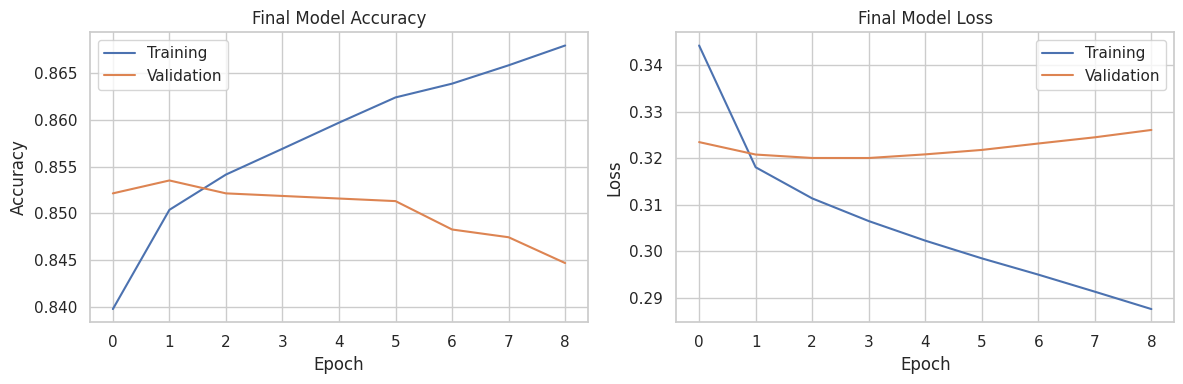

In [ ]:

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(final_history.history["accuracy"], label="Training")
plt.plot(final_history.history["val_accuracy"], label="Validation")
plt.title("Final Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(final_history.history["loss"], label="Training")
plt.plot(final_history.history["val_loss"], label="Validation")
plt.title("Final Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


### Interpretation: Final model training curves

Training accuracy climbs steadily and training loss falls, as expected. Validation accuracy peaks very early (about 85.3% in the second round) and then slowly slides, and validation loss bottoms out at round 3 or 4 and then starts to rise. The gap between the training and validation lines is the beginning of overfitting, and this is the point where early stopping ended the training.

The training run is short and the curves stop in good time, which is much healthier than the baseline curves from earlier in the notebook.

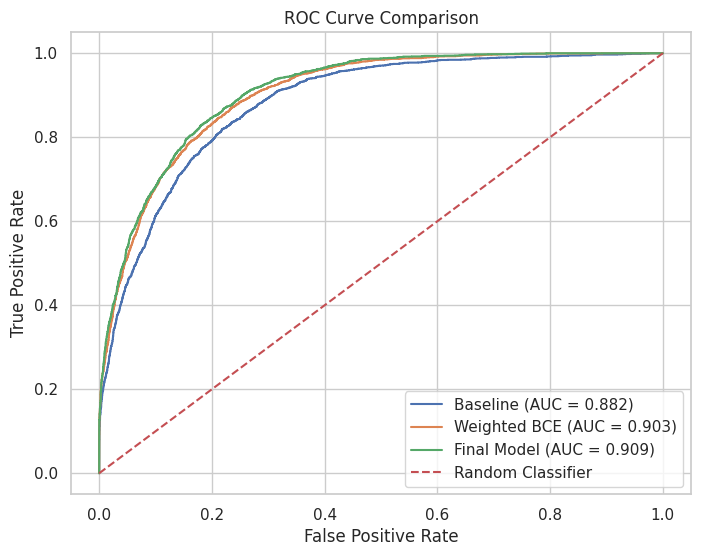

In [ ]:

from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Baseline model predictions
baseline_probabilities = baseline_model.predict(
    X_test_np, verbose=0
).ravel()

# Weighted BCE model from Task 5
weighted_bce_model = loss_models["Weighted BCE"]
weighted_probabilities = weighted_bce_model.predict(
    X_test_np, verbose=0
).ravel()

models_for_roc = {
    "Baseline": baseline_probabilities,
    "Weighted BCE": weighted_probabilities,
    "Final Model": final_probabilities
}

plt.figure(figsize=(8, 6))

for name, probabilities in models_for_roc.items():
    fpr, tpr, _ = roc_curve(y_test_np, probabilities)
    auc_value = roc_auc_score(y_test_np, probabilities)

    plt.plot(
        fpr, tpr,
        label=f"{name} (AUC = {auc_value:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)
plt.show()


### Interpretation: ROC curve comparison

The ROC curve shows how well a model separates the two income groups across all possible cut-off points. The higher a line bends toward the top-left corner, the better the model. The dashed diagonal is a model that guesses at random, with an area of 0.5.

- Baseline: 0.882
- Weighted BCE: 0.903
- Final model: 0.909

The final model is the best of the three and the baseline is the weakest, which fits what we saw in the training curves. The improvement from baseline to final model came mainly from stopping the training at the right time, before overfitting set in.

The Weighted BCE and final model curves are very close, so on ranking ability alone they are almost equal. The difference between them is in how they behave at the standard 0.5 cut-off: Weighted BCE finds more high earners but makes more false alarms, while the final model is more balanced.

Overall, the final model improved on the baseline in accuracy (82.7% to 85.0%), F1-score (0.62 to 0.68) and ROC-AUC (0.88 to 0.91), and it is the version to use for the project's conclusion.

## Conclusion:
 this project provided me with a practical understanding of how deep learning techniques can be applied to solve real-world classification problems. In this project, I used the Adult Income dataset to predict whether an individual's annual income is above or below $50K based on various features. I started by preparing and analyzing the dataset, then built and trained an Artificial Neural Network (ANN) model to make predictions.

I also explored different model configurations and evaluated their performance to understand how changes in the training process can affect the results. By comparing evaluation metrics, I gained a better understanding of how to measure a model's effectiveness and identify areas for improvement.

Overall, this project helped me strengthen my knowledge of Python, data preprocessing, neural networks, model training, and evaluation techniques. It also taught me the importance of choosing suitable parameters and carefully analyzing model results. This experience has improved my confidence in working on deep learning projects and provided a strong foundation for exploring more advanced machine learning techniques in the future.